# FIFA World Cup Project — Exploratory Data Analysis

## Research question
**What drives success for teams in the FIFA World Cup and what factors influence match outcomes?**

### Purpose of this notebook
This is a separate EDA notebook focused on analyses that complement, rather than duplicate, the team's existing `04_EDA.ipynb` work. The existing team EDA already investigates historical World Cup wins, appearances, tournament growth, historical wins versus 2026 FIFA rank, host-country success, historical goals per match, and composite team-attribute/radar analysis.

This notebook therefore concentrates on two linked questions:

1. **Team-level success (2026):** Which measurable characteristics are associated with stronger tournament performance?
2. **Match-level outcomes (historical World Cups and 2026 where appropriate):** Which match events are associated with winning?

The EDA is completed before machine learning. Its purpose is to understand distributions, relationships, potential confounding factors and useful candidate features before deciding what should enter a predictive model.

## Methodological principles

- Only **cleaned/processed datasets** are used.
- Cleaning decisions are not repeated or overwritten in this notebook.
- Team-name aliases are harmonised **in memory for merging only**; the processed CSVs are not changed.
- Historical identities such as West Germany, East Germany, the Soviet Union and Czechoslovakia are not globally rewritten. Historical naming is preserved where time context matters.
- Many 2026 performance datasets contain **tournament totals**. Teams progressing further play more matches, so raw totals can be misleading. Where appropriate, per-match measures are created before comparing teams.
- Correlation describes association, not causation.
- Missing event information is not imputed merely to make an analysis possible.
- Each section links directly back to the research question and records limitations relevant to interpretation and later modelling.

## Import libraries and locate the processed data

The project is expected to contain `data/processed`. The path logic below works whether Jupyter is started from the project root or from the `notebooks` folder.

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plasma_palette = sns.color_palette(palette='plasma')
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plasma_palette)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == 'notebooks' else CURRENT_DIR
PROCESSED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed'

print('Project root:', PROJECT_ROOT)
print('Processed data directory:', PROCESSED_DATA_DIR)
print('Directory exists:', PROCESSED_DATA_DIR.exists())

Project root: C:\Users\Hafsa\Desktop\Fifa-2026-World-Cup-Project
Processed data directory: C:\Users\Hafsa\Desktop\Fifa-2026-World-Cup-Project\data\processed
Directory exists: True


In [3]:

# This section was put in after the notebook was completed. This is saving all EDA plots into our separate 'plots' graph.

PLOTS_DIR = PROJECT_ROOT / 'plots'
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

original_show = plt.show
plot_counter = 0

def save_and_show(*args, **kwargs):
    global plot_counter

    for fig_num in plt.get_fignums():
        fig = plt.figure(fig_num)
        plot_counter += 1

        filename = f'05_EDA_plot_{plot_counter:02d}.png'

        fig.savefig(
            PLOTS_DIR / filename,
            dpi=300,
            bbox_inches='tight'
        )

    return original_show(*args, **kwargs)

plt.show = save_and_show

print('EDA plots will be saved to:', PLOTS_DIR.resolve())


EDA plots will be saved to: C:\Users\Hafsa\Desktop\Fifa-2026-World-Cup-Project\plots


## Load the cleaned datasets

All datasets are loaded explicitly so the analysis has a clear audit trail. The following checks confirm that the expected files are available and show their dimensions.

In [4]:
files = {
    'results': 'results_clean.csv',
    'goalscorers': 'goalscorers_clean.csv',
    'shootouts': 'shootouts_clean.csv',
    'former_names': 'former_names_clean.csv',
    'fixtures': 'wc_2026_fixtures_clean.csv',
    'teams': 'wc_2026_teams_clean.csv',
    'editions': 'wc_all_editions_clean.csv',
    'wc_matches': 'wc_all_matches_clean.csv',
    'top_scorers': 'wc_top_scorers_clean.csv',
    'attacking': 'attacking_clean.csv',
    'defending': 'defending_clean.csv',
    'discipline': 'discipline_clean.csv',
    'distribution': 'distribution_clean.csv',
    'goalkeeping': 'goalkeeping_clean.csv',
    'movement': 'movement_clean.csv',
    'physical': 'physical_clean.csv'
}

missing_files = [name for name in files.values() if not (PROCESSED_DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(f'Missing processed files: {missing_files}')

data = {key: pd.read_csv(PROCESSED_DATA_DIR / filename) for key, filename in files.items()}

for key, df in data.items():
    print(f'{key:12s}: {df.shape[0]:6,d} rows x {df.shape[1]:2d} columns')

results     : 49,509 rows x 15 columns
goalscorers : 47,886 rows x  9 columns
shootouts   :    682 rows x  6 columns
former_names:     36 rows x  4 columns
fixtures    :    104 rows x 15 columns
teams       :     48 rows x  7 columns
editions    :     22 rows x 20 columns
wc_matches  :    184 rows x 11 columns
top_scorers :     22 rows x 11 columns
attacking   :     48 rows x 14 columns
defending   :     48 rows x  8 columns
discipline  :     48 rows x  8 columns
distribution:     48 rows x 11 columns
goalkeeping :     48 rows x  9 columns
movement    :     48 rows x 10 columns
physical    :     48 rows x  5 columns


### Parse date columns used in the analysis

CSV files do not retain pandas datetime types after export. Dates needed for filtering and event matching are therefore converted back to datetime in memory. This is an analysis preparation step, not a correction to the cleaned data.

In [5]:
for key in ['results', 'goalscorers', 'shootouts', 'fixtures', 'wc_matches']:
    if 'date' in data[key].columns:
        data[key]['date'] = pd.to_datetime(data[key]['date'], errors='coerce')

for col in ['start_date', 'end_date']:
    data['editions'][col] = pd.to_datetime(data['editions'][col], errors='coerce')

print('Date parsing complete.')

Date parsing complete.


## Harmonise 2026 team aliases for merging

The cleaned 2026 performance files use several FIFA-style labels that differ from the naming convention used in the other cleaned project files. These are **aliases, not contradictory teams**.

The mapping is applied only to working copies in this notebook. This avoids rewriting historical identities and preserves the audit trail of the cleaning notebooks.

In [6]:
TEAM_ALIAS_TO_PROJECT = {
    'USA': 'United States',
    'Czechia': 'Czech Republic',
    'Cabo Verde': 'Cape Verde',
    'Congo DR': 'DR Congo',
    "Côte d'Ivoire": 'Ivory Coast',
    'IR Iran': 'Iran',
    'Korea Republic': 'South Korea',
    'Türkiye': 'Turkey'
}

performance_keys = ['attacking', 'defending', 'discipline', 'distribution', 'goalkeeping', 'movement', 'physical']
perf = {}
for key in performance_keys:
    perf[key] = data[key].copy()
    perf[key]['Team'] = perf[key]['Team'].replace(TEAM_ALIAS_TO_PROJECT)

project_teams = set(data['teams']['team'])
for key in performance_keys:
    unmatched = sorted(set(perf[key]['Team']) - project_teams)
    print(f'{key:12s} unmatched teams after alias mapping: {len(unmatched)}', unmatched)

attacking    unmatched teams after alias mapping: 0 []
defending    unmatched teams after alias mapping: 0 []
discipline   unmatched teams after alias mapping: 0 []
distribution unmatched teams after alias mapping: 0 []
goalkeeping  unmatched teams after alias mapping: 0 []
movement     unmatched teams after alias mapping: 0 []
physical     unmatched teams after alias mapping: 0 []


**Interpretation:** Every performance dataset should report zero unmatched teams. If so, all 48 teams can be linked consistently without changing the underlying cleaned files.

# What drives team success in the 2026 World Cup?

## Define team success before testing possible drivers

A key EDA decision is defining **success**. Using only `Champion = Yes/No` would reduce 48 teams to one winner and 47 non-winners, losing substantial information. Instead, this notebook creates several complementary outcome measures from the complete 2026 World Cup match results:

- `matches_played`: tournament exposure.
- `wins`: number of matches won in regulation/extra-time score data.
- `draws` and `losses`.
- `win_rate`: wins divided by matches played.
- `points_per_match`: a familiar 3/1/0 summary used here as a descriptive performance measure, not as official knockout-stage points.
- `goals_for_per_match`, `goals_against_per_match`, and `goal_difference_per_match`.
- `progression_measure`: how far the team progressed, derived from the 2026 fixture stage labels.

Using more than one outcome prevents the analysis from depending on a single arbitrary definition of success.

In [7]:
results_2026 = data['results'][
    (data['results']['tournament'] == 'FIFA World Cup') &
    (data['results']['year'] == 2026) &
    (data['results']['match_completed'] == True)
].copy()

print('Completed 2026 World Cup matches:', len(results_2026))
print('Date range:', results_2026['date'].min().date(), 'to', results_2026['date'].max().date())
print('Teams represented:', len(set(results_2026['home_team']) | set(results_2026['away_team'])))

Completed 2026 World Cup matches: 104
Date range: 2026-06-11 to 2026-07-19
Teams represented: 48


In [8]:
# Convert each match into one row per team so team-level results can be aggregated.
home = results_2026[['date','home_team','away_team','home_score','away_score']].copy()
home.columns = ['date','team','opponent','goals_for','goals_against']

away = results_2026[['date','away_team','home_team','away_score','home_score']].copy()
away.columns = ['date','team','opponent','goals_for','goals_against']

team_match_results = pd.concat([home, away], ignore_index=True)
team_match_results['win'] = (team_match_results['goals_for'] > team_match_results['goals_against']).astype(int)
team_match_results['draw'] = (team_match_results['goals_for'] == team_match_results['goals_against']).astype(int)
team_match_results['loss'] = (team_match_results['goals_for'] < team_match_results['goals_against']).astype(int)
team_match_results['points'] = team_match_results['win'] * 3 + team_match_results['draw']

team_success = team_match_results.groupby('team').agg(
    matches_played=('date','size'),
    wins=('win','sum'),
    draws=('draw','sum'),
    losses=('loss','sum'),
    goals_for=('goals_for','sum'),
    goals_against=('goals_against','sum'),
    points=('points','sum')
).reset_index()

team_success['win_rate'] = team_success['wins'] / team_success['matches_played']
team_success['points_per_match'] = team_success['points'] / team_success['matches_played']
team_success['goals_for_per_match'] = team_success['goals_for'] / team_success['matches_played']
team_success['goals_against_per_match'] = team_success['goals_against'] / team_success['matches_played']
team_success['goal_difference_per_match'] = (
    (team_success['goals_for'] - team_success['goals_against']) / team_success['matches_played']
)

team_success.sort_values(['wins','goal_difference_per_match'], ascending=False).head(10)

,team,matches_played,wins,draws,losses,goals_for,goals_against,points,win_rate,points_per_match,goals_for_per_match,goals_against_per_match,goal_difference_per_match
40,Spain,8,7,1,0,14,1,22,0.875,2.750,1.750,0.125,1.625
1,Argentina,8,7,0,1,19,8,21,0.875,2.625,2.375,1.000,1.375
17,France,8,6,0,2,20,10,18,0.750,2.250,2.500,1.250,1.250
16,England,8,6,1,1,20,12,19,0.750,2.375,2.500,1.500,1.000
26,Mexico,5,4,0,1,10,3,12,0.800,2.400,2.000,0.600,1.400
30,Norway,6,4,0,2,13,11,12,0.667,2.000,2.167,1.833,0.333
6,Brazil,5,3,1,1,10,4,10,0.600,2.000,2.000,0.800,1.200
4,Belgium,6,3,2,1,14,7,11,0.500,1.833,2.333,1.167,1.167
9,Colombia,5,3,2,0,5,1,11,0.600,2.200,1.000,0.200,0.800
27,Morocco,6,3,2,1,10,6,11,0.500,1.833,1.667,1.000,0.667


### Represent tournament progression

The cleaned fixture file contains structural placeholder labels for knockout participants rather than the realised team names, so it is **not used to assign a stage to individual teams**. Instead, `matches_played` is retained as a simple progression/exposure indicator: teams that advance further generally play more tournament matches.

This measure is not used as a predictor of success. It is a second descriptive outcome alongside `win_rate`, and cumulative performance statistics are still converted to per-match rates to avoid circular exposure effects.


In [9]:
# Inspect the relationship between matches played and other success measures.
team_success.sort_values(['matches_played','win_rate','goals_for_per_match'], ascending=False).head(12)


,team,matches_played,wins,draws,losses,goals_for,goals_against,points,win_rate,points_per_match,goals_for_per_match,goals_against_per_match,goal_difference_per_match
1,Argentina,8,7,0,1,19,8,21,0.875,2.625,2.375,1.000,1.375
40,Spain,8,7,1,0,14,1,22,0.875,2.750,1.750,0.125,1.625
16,England,8,6,1,1,20,12,19,0.750,2.375,2.500,1.500,1.000
17,France,8,6,0,2,20,10,18,0.750,2.250,2.500,1.250,1.250
30,Norway,6,4,0,2,13,11,12,0.667,2.000,2.167,1.833,0.333
4,Belgium,6,3,2,1,14,7,11,0.500,1.833,2.333,1.167,1.167
27,Morocco,6,3,2,1,10,6,11,0.500,1.833,1.667,1.000,0.667
42,Switzerland,6,3,2,1,10,6,11,0.500,1.833,1.667,1.000,0.667
26,Mexico,5,4,0,1,10,3,12,0.800,2.400,2.000,0.600,1.400
45,United States,5,3,0,2,11,8,9,0.600,1.800,2.200,1.600,0.600


### Visualise the distribution of 2026 success

Before testing explanatory variables, we inspect how much variation exists in the outcome itself. This helps identify whether the chosen success measures meaningfully distinguish teams.

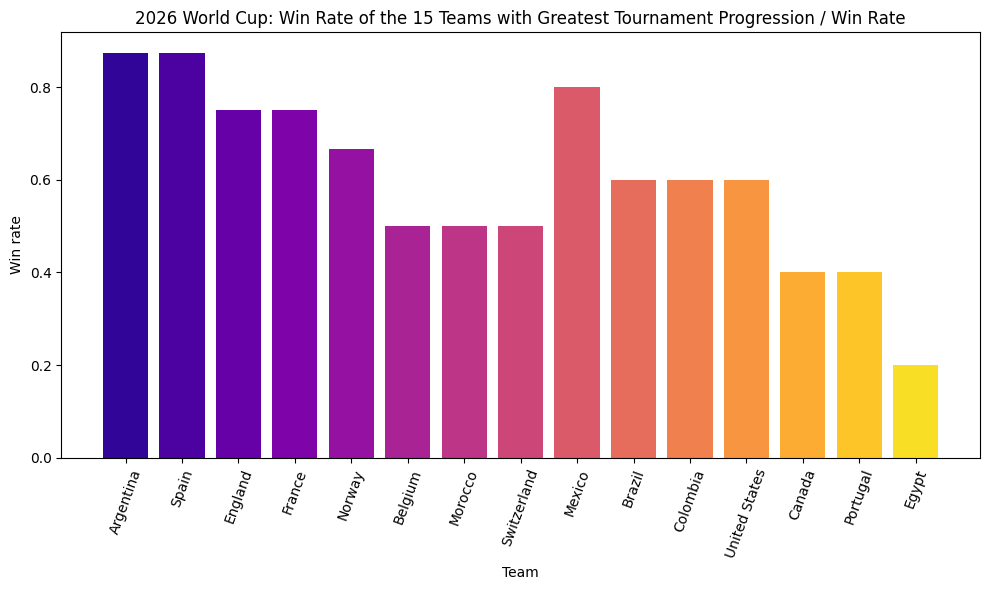

,matches_played,wins,win_rate,points_per_match,matches_played
count,48.000,48.000,48.000,48.000,48.000
mean,4.333,1.667,0.312,1.177,4.333
std,1.449,1.860,0.266,0.753,1.449
min,3.000,0.000,0.000,0.000,3.000
25%,3.000,0.000,0.000,0.729,3.000
50%,4.000,1.000,0.250,1.000,4.000
75%,5.000,2.250,0.500,1.808,5.000
max,8.000,7.000,0.875,2.750,8.000


In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_df = team_success.sort_values(['matches_played','win_rate'], ascending=False).head(15)
ax.bar(
    plot_df['team'],
    plot_df['win_rate'],
    color=sns.color_palette('plasma', n_colors=len(plot_df))
)
ax.set_title('2026 World Cup: Win Rate of the 15 Teams with Greatest Tournament Progression / Win Rate')
ax.set_xlabel('Team')
ax.set_ylabel('Win rate')
ax.tick_params(axis='x', rotation=70)
plt.tight_layout()
plt.show()

team_success[['matches_played','wins','win_rate','points_per_match','matches_played']].describe().round(3)

**What to look for:** Success is not distributed evenly. Later-stage teams should generally have more matches played, while win rate and points per match provide exposure-adjusted measures. This is why later analyses do not rely only on raw tournament totals.

## Build one 2026 team-level analysis table

The seven detailed performance datasets are merged with FIFA ranking/confederation information and the success outcomes above. This produces one row per 2026 team.

Raw cumulative statistics are retained, but selected **per-match features** are added. This is crucial because a finalist has more opportunities to accumulate passes, shots, fouls, distance and other totals than a team eliminated early.

In [11]:
team_eda = data['teams'].rename(columns={'team':'Team'}).copy()

for key in performance_keys:
    team_eda = team_eda.merge(perf[key], on='Team', how='left', suffixes=('', f'_{key}'))

team_eda = team_eda.merge(team_success.rename(columns={'team':'Team'}), on='Team', how='left')

# GoalsConceded exists in both defending and goalkeeping; the cleaning validation confirmed agreement.
# Remove any duplicated suffixed version created by the merge if present.
for c in [c for c in team_eda.columns if c.startswith('GoalsConceded_')]:
    team_eda.drop(columns=c, inplace=True)

print('Team-level EDA table shape:', team_eda.shape)
print('Teams with missing success data:', team_eda['wins'].isna().sum())
team_eda.head()

Team-level EDA table shape: (48, 76)
Teams with missing success data: 0


,Team,group,confederation,fifa_rank,coach,best_wc_result,debut_2026,Goals,Assists,AttemptsAtGoal,AttemptsOnTarget,AttemptsOffTarget,AttemptsAtGoalConversionRatePC,AttemptsInsideThePenaltyArea,AttemptsOutsideThePenaltyArea,HeadedAttemptsAtGoal,xG,xGEfficiency,Corners,PossessionControlPC,OwnGoals,GoalsConceded,ForcedTurnovers,BallRecoveryTime,DefensivePressuresApplied,DefensivePressuresDirectlyApplied,DirectDefensivePressurePC,FoulsAgainst,FoulsFor,YellowCards,RedCards,IndirectRedCards,Offsides,IndirectRedCardPC,Passes,PassesCompleted,PassingAccuracyPC,Crosses,CrossingAccuracyPC,TakeOnsCompleted,DefensiveLineBreaksAttempted,DefensiveLineBreaksAccPC,SwitchesOfPlayAttempted,SwitchesOfPlayAccPC,CleanSheets,GoalkeeperSaves,GoalkeeperActionsInsideThePenaltyArea,GoalkeeperActionsOutsideThePenaltyArea,TotalGoalkeeperActions,InsidePenaltyAreaPC,OutsidePenaltyAreaPC,OffersToReceive,OffersInBehind,OffersInBetween,OffersInFront,OffersInsideTeamShape,OffersOutsideTeamShape,ReceptionsInBehind,ReceptionsBetweenMidfieldAndDefensiveLine,ReceptionsUnderPressure,AverageSpeed,HighSpeedRunning,Sprints,TotalDistance,matches_played,wins,draws,losses,goals_for,goals_against,points,win_rate,points_per_match,goals_for_per_match,goals_against_per_match,goal_difference_per_match
0,Mexico,A,CONCACAF,15,Javier Aguirre,"Quarter-finals (1970,1986)",No,10,7,70,21,32,14,44,26,13,8.100,1.230,19,48,0,3,178,73.860,1065,177,16.600,58,48,4,1,0,5,0.000,2175,1902,87,91,26,27,89,42,28,89,4,8,60,49,109,55.000,45.000,2034,541,844,649,1076,958,40,505,834,6.010,6354,2190,563.844,5,4,0,1,10,3,12,0.800,2.400,2.000,0.600,1.400
1,South Africa,A,CAF,60,Hugo Broos,"Group stage (1998,2002,2010)",No,2,1,39,11,18,5,13,26,5,2.480,0.800,11,46,0,4,158,73.070,1081,166,15.400,38,46,5,2,0,8,0.000,1855,1573,85,36,17,21,63,41,27,85,1,14,72,59,131,55.000,45.000,1212,359,458,395,669,543,29,283,634,5.900,5039,1884,429.069,4,1,1,2,2,4,4,0.250,1.000,0.500,1.000,-0.500
2,South Korea,A,AFC,25,Hong Myung-bo,Semi-finals (2002),No,2,2,32,11,13,6,21,11,9,3.380,0.590,12,56,0,3,106,44.640,563,86,15.300,25,32,4,0,0,8,NaN,1853,1650,89,64,28,23,65,60,21,86,0,11,42,34,76,55.300,44.700,1201,267,427,507,657,544,40,274,678,6.090,3553,1298,334.955,3,1,0,2,2,3,3,0.333,1.000,0.667,1.000,-0.333
3,Czech Republic,A,UEFA,41,Ivan Hasek,"Runner-up (1934,1962)",No,2,2,34,8,15,6,22,12,10,2.440,0.820,15,37,0,6,119,56.670,857,121,14.100,37,31,1,0,0,5,NaN,1102,872,79,50,32,19,45,38,12,75,0,11,60,52,112,53.600,46.400,740,232,305,203,371,369,19,245,439,6.330,4330,1381,348.826,3,0,1,2,2,6,1,0.000,0.333,0.667,2.000,-1.333
4,Canada,B,CONCACAF,30,Jesse Marsch,"Group stage (1986,2022)",No,9,3,81,32,29,11,57,24,16,9.020,1.000,50,46,0,6,228,66.430,1183,228,19.300,72,71,11,0,0,7,NaN,2098,1722,82,158,24,32,119,55,18,83,2,7,49,40,89,55.100,44.900,1589,533,576,480,790,799,72,540,929,6.100,6943,2560,570.460,5,2,1,2,9,6,7,0.400,1.400,1.800,1.200,0.600


In [12]:
# Tournament totals where a per-match version is meaningful.
per_match_columns = [
    'Goals','Assists','AttemptsAtGoal','AttemptsOnTarget','AttemptsOffTarget',
    'AttemptsInsideThePenaltyArea','AttemptsOutsideThePenaltyArea','HeadedAttemptsAtGoal',
    'Corners','OwnGoals','GoalsConceded','ForcedTurnovers','DefensivePressuresApplied',
    'DefensivePressuresDirectlyApplied','FoulsAgainst','FoulsFor','YellowCards','RedCards',
    'IndirectRedCards','Offsides','Passes','PassesCompleted','Crosses','TakeOnsCompleted',
    'DefensiveLineBreaksAttempted','SwitchesOfPlayAttempted','CleanSheets','GoalkeeperSaves',
    'GoalkeeperActionsInsideThePenaltyArea','GoalkeeperActionsOutsideThePenaltyArea',
    'TotalGoalkeeperActions','OffersToReceive','OffersInBehind','OffersInBetween','OffersInFront',
    'OffersInsideTeamShape','OffersOutsideTeamShape','ReceptionsInBehind',
    'ReceptionsBetweenMidfieldAndDefensiveLine','ReceptionsUnderPressure','HighSpeedRunning',
    'Sprints','TotalDistance'
]

for col in per_match_columns:
    if col in team_eda.columns:
        team_eda[f'{col}_per_match'] = team_eda[col] / team_eda['matches_played']

print('Per-match features created:', sum(c.endswith('_per_match') for c in team_eda.columns))

Per-match features created: 47


## Does 2026 FIFA ranking relate to 2026 success?

The existing team EDA compares **2026 FIFA rank with historical World Cup wins**. This section asks a different and more temporally aligned question: does the ranking entering the 2026 tournament relate to performance in the 2026 tournament itself?

Because a lower numerical FIFA rank means a stronger ranking (1 is better than 50), a negative correlation between rank and success would indicate that better-ranked teams tend to perform better.

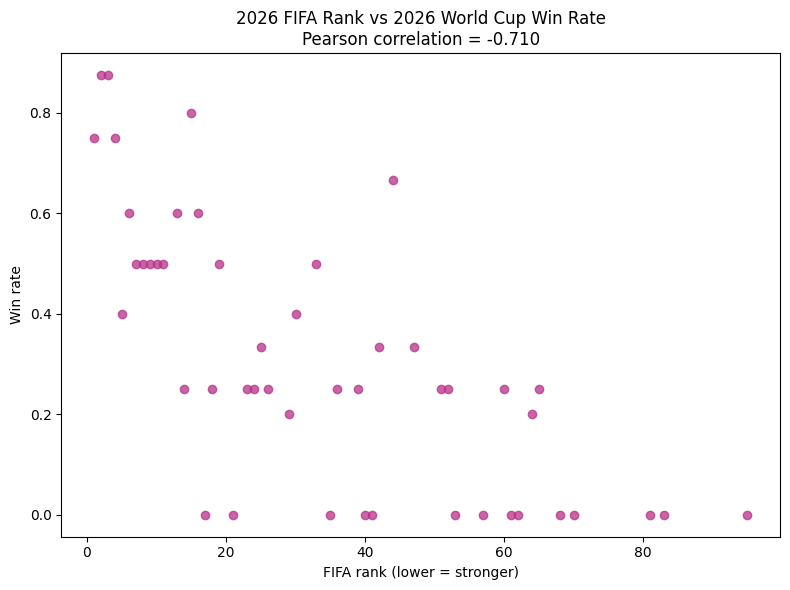

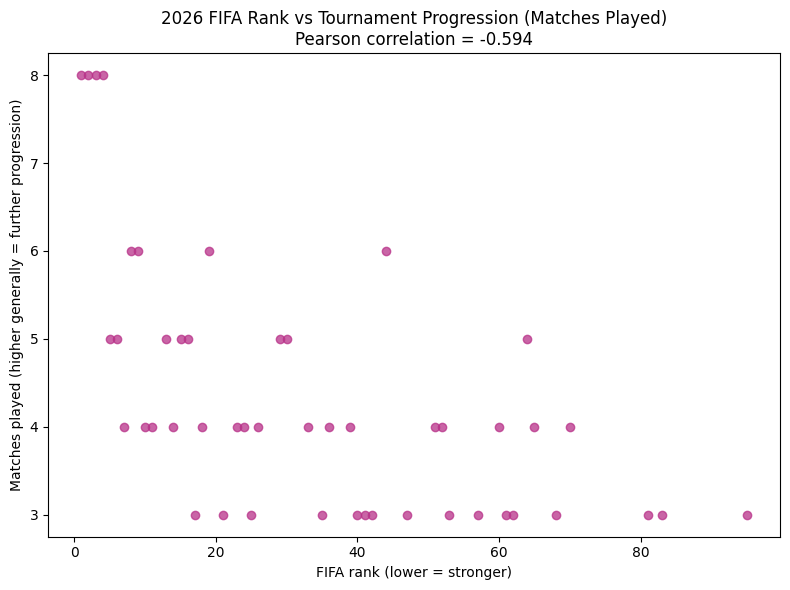

Rank vs win rate correlation: -0.710
Rank vs tournament progression (matches played) correlation: -0.594


In [13]:
def scatter_with_corr(df, x, y, title, xlabel=None, ylabel=None):
    temp = df[[x,y]].dropna()
    corr = temp[x].corr(temp[y])
    fig, ax = plt.subplots(figsize=(8,6))
    ax.scatter(
    temp[x],
    temp[y],
    alpha=0.75,
    color=plasma_palette[2]
)
    ax.set_title(f'{title}\nPearson correlation = {corr:.3f}')
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel or y)
    plt.tight_layout()
    plt.show()
    return corr

rank_win_corr = scatter_with_corr(
    team_eda, 'fifa_rank', 'win_rate',
    '2026 FIFA Rank vs 2026 World Cup Win Rate',
    'FIFA rank (lower = stronger)', 'Win rate'
)

rank_stage_corr = scatter_with_corr(
    team_eda, 'fifa_rank', 'matches_played',
    '2026 FIFA Rank vs Tournament Progression (Matches Played)',
    'FIFA rank (lower = stronger)', 'Matches played (higher generally = further progression)'
)

print(f'Rank vs win rate correlation: {rank_win_corr:.3f}')
print(f'Rank vs tournament progression (matches played) correlation: {rank_stage_corr:.3f}')

**Interpretation guide:** A negative relationship is expected if stronger FIFA rankings are associated with greater success. The magnitude matters more than the sign alone. A weak relationship would suggest that ranking captures only part of what determines tournament performance; a stronger relationship would support its use as a team-strength feature later. Do not describe correlation as proof that ranking causes success.

## Attacking performance: volume or efficiency?

This section tests whether successful teams are characterised more by **creating many attempts** or by **using chances efficiently**. It directly addresses the question: *Does stronger attacking performance increase tournament success, and does efficiency matter more than shot volume?*

Useful attacking indicators include attempts per match, attempts on target per match, conversion rate, xG, xG efficiency and goals per match. Percentage/efficiency variables are already rate-like and are not divided by matches played.

In [14]:
attack_features = [
    'AttemptsAtGoal_per_match',
    'AttemptsOnTarget_per_match',
    'AttemptsAtGoalConversionRatePC',
    'xG',
    'xGEfficiency',
    'PossessionControlPC'
]

attack_corr = (team_eda[attack_features + ['win_rate','matches_played']]
               .corr(numeric_only=True)[['win_rate','matches_played']]
               .drop(['win_rate','matches_played'], errors='ignore')
               .sort_values('win_rate', key=lambda s: s.abs(), ascending=False))
attack_corr

,win_rate,matches_played
xG,0.847,0.906
AttemptsOnTarget_per_match,0.692,0.636
PossessionControlPC,0.675,0.477
AttemptsAtGoal_per_match,0.527,0.439
AttemptsAtGoalConversionRatePC,0.464,0.424
xGEfficiency,0.121,0.159


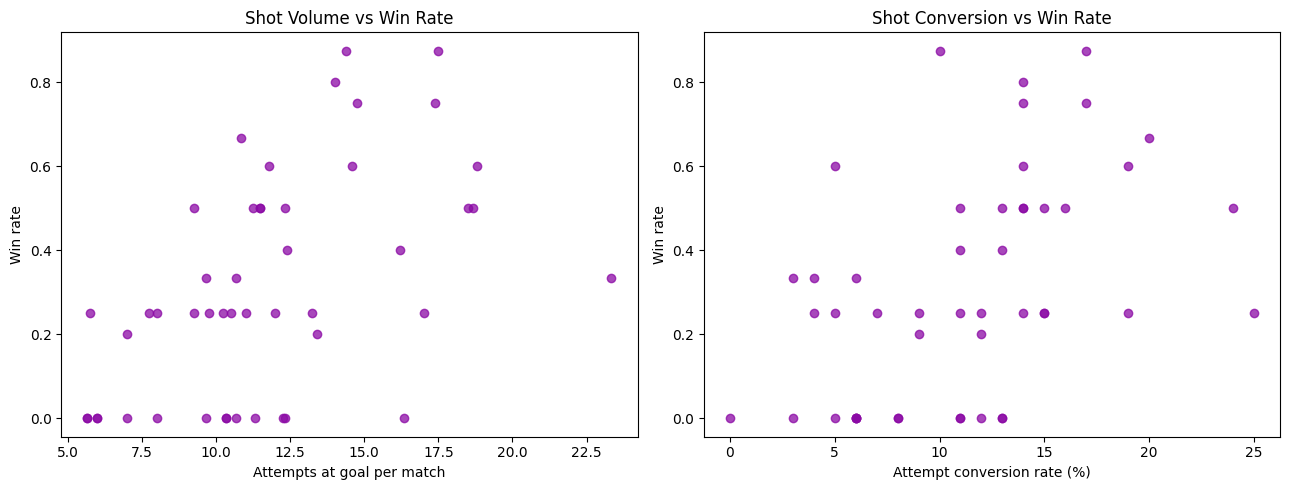

Shot volume correlation: 0.527
Conversion correlation: 0.464


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].scatter(team_eda['AttemptsAtGoal_per_match'], team_eda['win_rate'], alpha=.75,color=plasma_palette[1])
axes[0].set_title('Shot Volume vs Win Rate')
axes[0].set_xlabel('Attempts at goal per match')
axes[0].set_ylabel('Win rate')

axes[1].scatter(team_eda['AttemptsAtGoalConversionRatePC'], team_eda['win_rate'], alpha=.75,color=plasma_palette[1])
axes[1].set_title('Shot Conversion vs Win Rate')
axes[1].set_xlabel('Attempt conversion rate (%)')
axes[1].set_ylabel('Win rate')
plt.tight_layout()
plt.show()

print('Shot volume correlation:', round(team_eda['AttemptsAtGoal_per_match'].corr(team_eda['win_rate']),3))
print('Conversion correlation:', round(team_eda['AttemptsAtGoalConversionRatePC'].corr(team_eda['win_rate']),3))

**How to interpret this section:** Compare both direction and magnitude. If conversion rate has a stronger association with success than attempts per match, the data suggests efficiency distinguishes successful teams more clearly than simply producing a high volume of shots. If the opposite occurs, shot creation may be more informative. This remains an association and should later be tested alongside other variables rather than in isolation.

## Defensive and goalkeeping performance

A team can succeed by scoring more, conceding less, or both. Here we test whether defensive indicators distinguish successful teams.

`GoalsConceded_per_match` is particularly useful because it adjusts for tournament exposure. Clean sheets are also converted to a per-match rate. Goalkeeper saves require care: many saves can indicate good goalkeeping, but can also indicate that a team allows opponents many shots.

In [16]:
team_eda['clean_sheet_rate'] = team_eda['CleanSheets'] / team_eda['matches_played']

defence_features = [
    'GoalsConceded_per_match','clean_sheet_rate','ForcedTurnovers_per_match',
    'BallRecoveryTime','DirectDefensivePressurePC','GoalkeeperSaves_per_match',
    'OutsidePenaltyAreaPC'
]

defence_corr = (team_eda[defence_features + ['win_rate','matches_played']]
                .corr(numeric_only=True)[['win_rate','matches_played']]
                .drop(['win_rate','matches_played'], errors='ignore')
                .sort_values('win_rate', key=lambda s: s.abs(), ascending=False))
defence_corr

,win_rate,matches_played
BallRecoveryTime,0.648,0.845
GoalsConceded_per_match,-0.598,-0.487
clean_sheet_rate,0.513,0.473
GoalkeeperSaves_per_match,-0.450,-0.308
DirectDefensivePressurePC,0.108,0.045
OutsidePenaltyAreaPC,-0.105,-0.125
ForcedTurnovers_per_match,-0.086,0.107


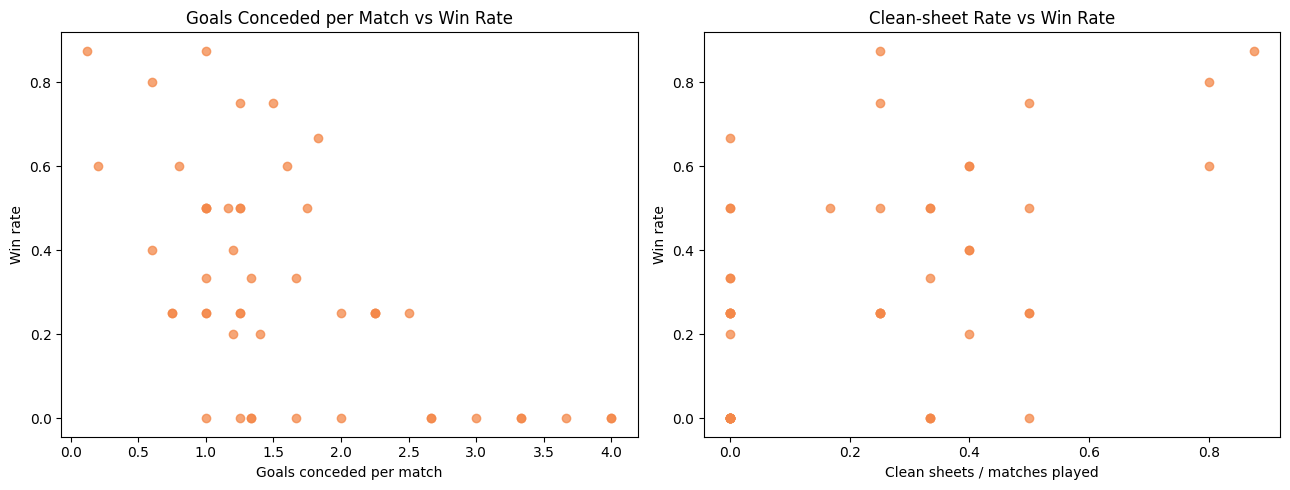

In [17]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].scatter(team_eda['GoalsConceded_per_match'], team_eda['win_rate'], alpha=.75,color=plasma_palette[4])
axes[0].set_title('Goals Conceded per Match vs Win Rate')
axes[0].set_xlabel('Goals conceded per match')
axes[0].set_ylabel('Win rate')

axes[1].scatter(team_eda['clean_sheet_rate'], team_eda['win_rate'], alpha=.75,color=plasma_palette[4])
axes[1].set_title('Clean-sheet Rate vs Win Rate')
axes[1].set_xlabel('Clean sheets / matches played')
axes[1].set_ylabel('Win rate')
plt.tight_layout()
plt.show()

**Interpretation guide:** For goals conceded, a negative correlation with success indicates stronger defensive performance is associated with winning. For clean-sheet rate, a positive correlation would support the same conclusion. Saves should not automatically be interpreted as defensive strength because they partly measure exposure to opposition shots.

## Distribution, physical performance, movement and discipline

The project contains unusually detailed 2026 team metrics. Rather than plotting every column, this section tests a targeted set of interpretable measures against win rate. This avoids producing many redundant graphs and keeps the analysis tied to the research question.

The selected measures represent:
- **Distribution:** passing accuracy and line-breaking accuracy.
- **Physical:** average speed, sprints per match and distance per match.
- **Movement:** receptions/receiving actions per match.
- **Discipline:** cards and fouls per match.

In [18]:
secondary_features = [
    'PassingAccuracyPC','CrossingAccuracyPC','DefensiveLineBreaksAccPC',
    'AverageSpeed','Sprints_per_match','TotalDistance_per_match',
    'OffersToReceive_per_match','ReceptionsUnderPressure_per_match',
    'YellowCards_per_match','RedCards_per_match','FoulsAgainst_per_match','Offsides_per_match'
]

secondary_corr = (team_eda[secondary_features + ['win_rate','matches_played']]
                  .corr(numeric_only=True)[['win_rate','matches_played']]
                  .drop(['win_rate','matches_played'], errors='ignore'))
secondary_corr['abs_win_rate_corr'] = secondary_corr['win_rate'].abs()
secondary_corr.sort_values('abs_win_rate_corr', ascending=False)

,win_rate,matches_played,abs_win_rate_corr
PassingAccuracyPC,0.675,0.470,0.675
OffersToReceive_per_match,0.602,0.474,0.602
DefensiveLineBreaksAccPC,0.567,0.470,0.567
ReceptionsUnderPressure_per_match,0.393,0.253,0.393
YellowCards_per_match,-0.297,-0.156,0.297
TotalDistance_per_match,0.286,0.316,0.286
AverageSpeed,-0.125,-0.197,0.125
RedCards_per_match,-0.086,-0.024,0.086
Offsides_per_match,0.077,0.066,0.077
FoulsAgainst_per_match,0.028,0.076,0.028


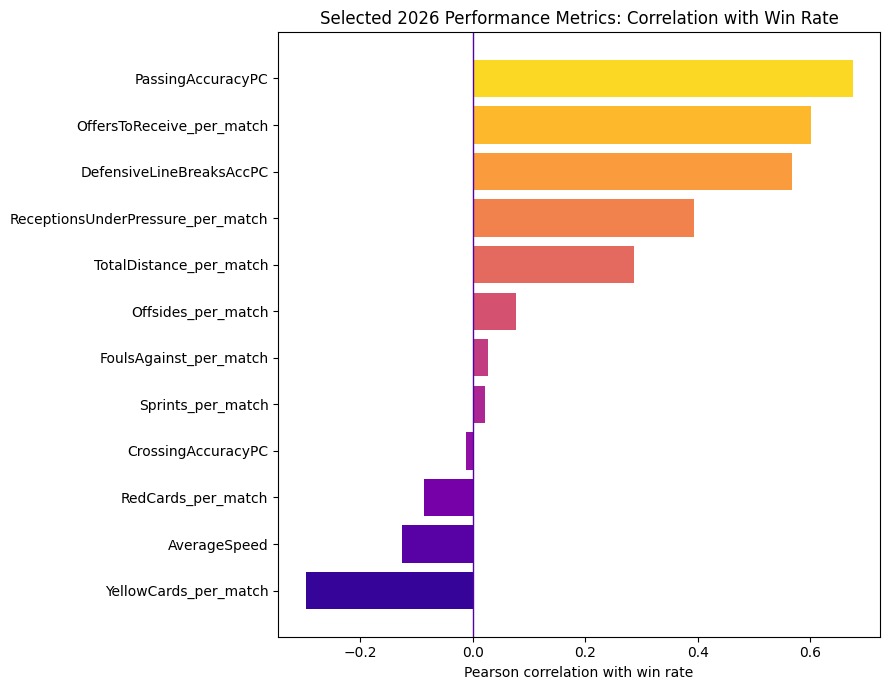

In [19]:
plot_corr = secondary_corr.sort_values('win_rate')['win_rate']
fig, ax = plt.subplots(figsize=(9,7))
ax.barh(
    plot_corr.index,
    plot_corr.values,
    color=sns.color_palette('plasma', n_colors=len(plot_corr))
)
ax.axvline(0, linewidth=1)
ax.set_title('Selected 2026 Performance Metrics: Correlation with Win Rate')
ax.set_xlabel('Pearson correlation with win rate')
plt.tight_layout()
plt.show()

**Interpretation guide:** Focus on the strongest positive and negative relationships rather than treating every small coefficient as meaningful. Cumulative metrics have been converted to per-match values where appropriate. Percentage measures such as passing accuracy remain as percentages because they are already normalised measures.

## Are some confederations more successful in 2026?

This is a descriptive comparison of team performance by confederation. It can reveal broad regional patterns, but sample sizes differ substantially between confederations and some contain very few teams. Therefore the result should not be interpreted as proof that confederation itself causes success.

In [20]:
confed_summary = (team_eda.groupby('confederation')
                  .agg(teams=('Team','nunique'),
                       mean_win_rate=('win_rate','mean'),
                       mean_matches_played=('matches_played','mean'),
                       mean_fifa_rank=('fifa_rank','mean'))
                  .sort_values('mean_win_rate', ascending=False))
confed_summary.round(3)

,teams,mean_win_rate,mean_matches_played,mean_fifa_rank
confederation,,,,
UEFA,16,0.460,5.000,22.250
CONMEBOL,6,0.421,5.000,21.167
CONCACAF,6,0.300,4.000,46.333
CAF,10,0.245,4.200,40.600
AFC,9,0.093,3.222,41.444
OFC,1,0.000,3.000,95.000


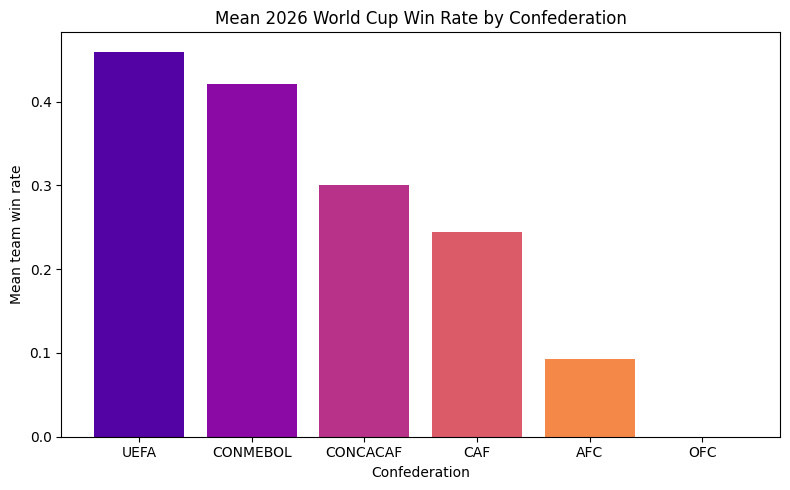

In [21]:
fig, ax = plt.subplots(figsize=(8,5))
cs = confed_summary.sort_values('mean_win_rate', ascending=False)
ax.bar(
    cs.index,
    cs['mean_win_rate'],
    color=sns.color_palette('plasma', n_colors=len(cs))
)
ax.set_title('Mean 2026 World Cup Win Rate by Confederation')
ax.set_xlabel('Confederation')
ax.set_ylabel('Mean team win rate')
plt.tight_layout()
plt.show()

# What factors influence individual World Cup match outcomes?

Team-level tournament statistics answer only part of the research question. We now change the unit of analysis from **one row per team** to **one row per match**. Event data from `goalscorers_clean.csv` can then be linked to World Cup results to examine whether scoring first, goal timing, penalties and own goals are associated with match outcomes.

## Prepare completed historical World Cup matches

Only completed FIFA World Cup matches with known scores are included. This avoids treating structurally missing scores as real results. Historical team names are left unchanged.

In [22]:
wc_results = data['results'][
    (data['results']['tournament'] == 'FIFA World Cup') &
    (data['results']['match_completed'] == True) &
    data['results']['home_score'].notna() &
    data['results']['away_score'].notna()
].copy()

print('Completed World Cup matches available:', len(wc_results))
print('Years:', int(wc_results['year'].min()), 'to', int(wc_results['year'].max()))
print(wc_results['result'].value_counts(dropna=False))

Completed World Cup matches available: 1068
Years: 1930 to 2026
result
Home Win    488
Away Win    342
Draw        238
Name: count, dtype: int64


## Does scoring first influence the probability of winning?

For each World Cup match with usable goal-event information, the earliest recorded goal is identified. The scorer's `team` field identifies the team credited with the goal. For an own goal, the scoring credit still belongs to the benefiting team in this dataset, so it remains appropriate for determining which side went 1–0 ahead.

Matches with no usable goal minute cannot reliably identify who scored first and are excluded from this specific analysis rather than imputed.

In [23]:
wc_keys = wc_results[['date','home_team','away_team']].drop_duplicates()
wc_goals = data['goalscorers'].merge(wc_keys, on=['date','home_team','away_team'], how='inner')
usable_goals = wc_goals[wc_goals['minute'].notna()].copy()

first_goals = (usable_goals.sort_values(['date','home_team','away_team','minute'])
               .groupby(['date','home_team','away_team'], as_index=False)
               .first()[['date','home_team','away_team','team','minute']]
               .rename(columns={'team':'first_scorer_team','minute':'first_goal_minute'}))

first_goal_matches = wc_results.merge(first_goals, on=['date','home_team','away_team'], how='inner')

first_goal_matches['first_scorer_won'] = np.where(
    (first_goal_matches['first_scorer_team'] == first_goal_matches['home_team']) & (first_goal_matches['home_score'] > first_goal_matches['away_score']), True,
    np.where((first_goal_matches['first_scorer_team'] == first_goal_matches['away_team']) & (first_goal_matches['away_score'] > first_goal_matches['home_score']), True, False)
)
first_goal_matches['ended_draw'] = first_goal_matches['home_score'] == first_goal_matches['away_score']
first_goal_matches['first_scorer_lost'] = (~first_goal_matches['first_scorer_won']) & (~first_goal_matches['ended_draw'])

summary = pd.Series({
    'matches_with_identifiable_first_goal': len(first_goal_matches),
    'first_scorer_won': first_goal_matches['first_scorer_won'].sum(),
    'ended_draw': first_goal_matches['ended_draw'].sum(),
    'first_scorer_lost': first_goal_matches['first_scorer_lost'].sum(),
    'win_probability_after_scoring_first': first_goal_matches['first_scorer_won'].mean()
})
summary

matches_with_identifiable_first_goal   974.000
first_scorer_won                       691.000
ended_draw                             152.000
first_scorer_lost                      131.000
win_probability_after_scoring_first      0.709
dtype: float64

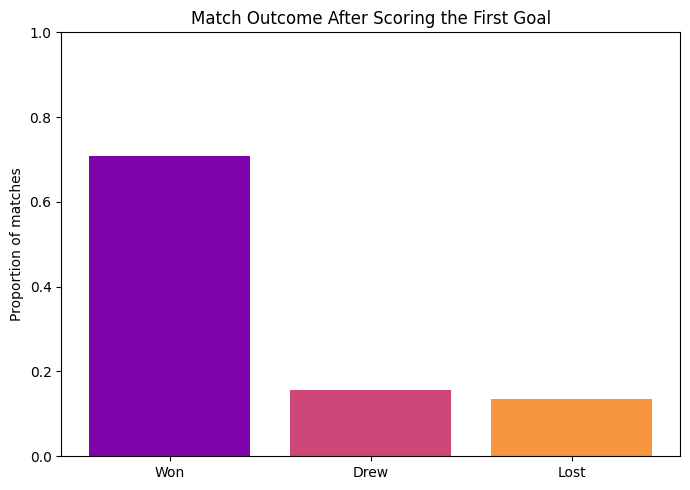

Won    70.900
Drew   15.600
Lost   13.400
Name: Percentage, dtype: float64

In [24]:
outcome_rates = pd.Series({
    'Won': first_goal_matches['first_scorer_won'].mean(),
    'Drew': first_goal_matches['ended_draw'].mean(),
    'Lost': first_goal_matches['first_scorer_lost'].mean()
})
fig, ax = plt.subplots(figsize=(7,5))
ax.bar(
    outcome_rates.index,
    outcome_rates.values,
    color=sns.color_palette('plasma', n_colors=len(outcome_rates))
)
ax.set_title('Match Outcome After Scoring the First Goal')
ax.set_ylabel('Proportion of matches')
ax.set_ylim(0,1)
plt.tight_layout()
plt.show()

(outcome_rates * 100).round(1).rename('Percentage')

**Interpretation guide:** The key result is the observed proportion of matches won by the team scoring first. A high value indicates a strong association between taking the lead and the final outcome. It does **not** establish causality because stronger teams may both score first and be more likely to win.

## Does the timing of the first goal matter?

The first-goal analysis is extended by grouping the minute of the opening goal into match periods. This tests whether an early lead is associated with a different win rate from a late lead.

Added-time minutes can exceed 45 or 90 in the source data, so bins are deliberately broad enough to retain those observations rather than deleting them.

In [25]:
bins = [0, 15, 30, 45, 60, 75, 90, np.inf]
labels = ['1–15','16–30','31–45','46–60','61–75','76–90','90+']
first_goal_matches['first_goal_period'] = pd.cut(
    first_goal_matches['first_goal_minute'], bins=bins, labels=labels, include_lowest=True
)

timing_summary = (first_goal_matches.groupby('first_goal_period', observed=False)
                  .agg(matches=('first_scorer_won','size'),
                       win_rate_after_scoring_first=('first_scorer_won','mean'),
                       median_first_goal_minute=('first_goal_minute','median')))
timing_summary

,matches,win_rate_after_scoring_first,median_first_goal_minute
first_goal_period,,,
1–15,330,0.664,8.000
16–30,227,0.648,22.000
31–45,158,0.722,38.000
46–60,119,0.714,52.000
61–75,67,0.881,66.000
76–90,60,0.917,83.000
90+,13,0.923,113.000


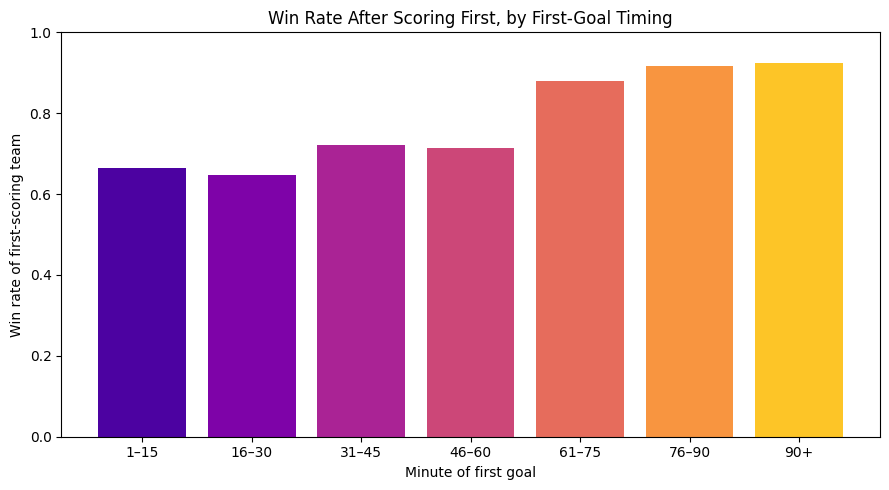

In [26]:
fig, ax = plt.subplots(figsize=(9,5))
ax.bar(
    timing_summary.index.astype(str),
    timing_summary['win_rate_after_scoring_first'],
    color=sns.color_palette('plasma', n_colors=len(timing_summary))
)
ax.set_title('Win Rate After Scoring First, by First-Goal Timing')
ax.set_xlabel('Minute of first goal')
ax.set_ylabel('Win rate of first-scoring team')
ax.set_ylim(0,1)
plt.tight_layout()
plt.show()

**Interpretation guide:** Looking for a consistent pattern rather than over-interpreting one small time bin. The `matches` column is important: a rate based on few matches is less stable than one based on many observations.

## Penalties and own goals in World Cup matches

Penalty goals and own goals are relatively uncommon events. The aim is therefore descriptive: measure their frequency and compare outcomes in matches containing these events with matches that do not. This section should not imply that a rare event is a general causal driver without sufficient evidence.

In [27]:
event_flags = (wc_goals.groupby(['date','home_team','away_team'])
               .agg(penalty_goals=('penalty','sum'), own_goals=('own_goal','sum'))
               .reset_index())

wc_event_matches = wc_results.merge(event_flags, on=['date','home_team','away_team'], how='left')
wc_event_matches[['penalty_goals','own_goals']] = wc_event_matches[['penalty_goals','own_goals']].fillna(0)
wc_event_matches['has_penalty_goal'] = wc_event_matches['penalty_goals'] > 0
wc_event_matches['has_own_goal'] = wc_event_matches['own_goals'] > 0

pd.DataFrame({
    'Matches': [len(wc_event_matches), wc_event_matches['has_penalty_goal'].sum(), wc_event_matches['has_own_goal'].sum()],
    'Percentage_of_WC_matches': [100, wc_event_matches['has_penalty_goal'].mean()*100, wc_event_matches['has_own_goal'].mean()*100]
}, index=['All completed WC matches','With penalty goal','With own goal']).round(2)

,Matches,Percentage_of_WC_matches
All completed WC matches,1068,100.000
With penalty goal,202,18.910
With own goal,67,6.270


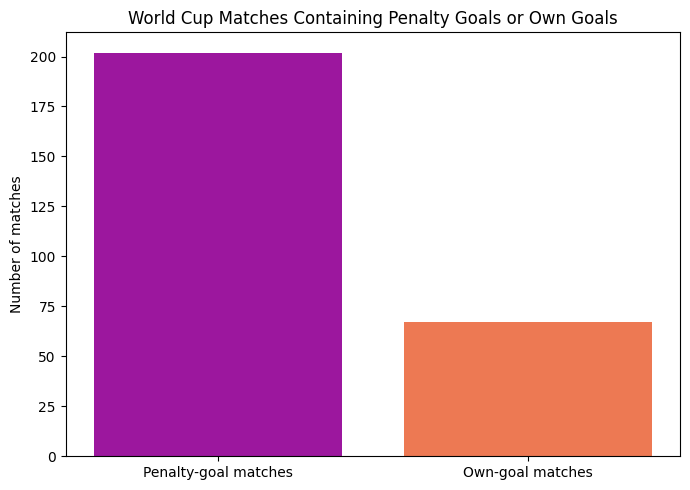

In [28]:

fig, ax = plt.subplots(figsize=(7,5))

counts = pd.Series({
    'Penalty-goal matches': wc_event_matches['has_penalty_goal'].sum(),
    'Own-goal matches': wc_event_matches['has_own_goal'].sum()
})

ax.bar(
    counts.index,
    counts.values,
    color=sns.color_palette('plasma', n_colors=len(counts))
)

ax.set_title('World Cup Matches Containing Penalty Goals or Own Goals')
ax.set_ylabel('Number of matches')
plt.tight_layout()
plt.show()


**Interpretation guide:** Report prevalence first. Because these events are much less common than ordinary goals, avoid claiming they are among the strongest general drivers of match outcomes based only on raw counts.

## Penalty shootouts: does shooting first relate to winning?

The shootout dataset contains the winner and, for some records, the first shooter. The cleaning process deliberately retained missing `first_shooter` values rather than imputing them. This analysis therefore uses **only rows where `first_shooter_known == True`**.

This answers a focused match-outcome question without changing the missing-data decision made during cleaning.

In [29]:
shootouts_known = data['shootouts'][
    (data['shootouts']['first_shooter_known'] == True) &
    data['shootouts']['first_shooter'].notna()
].copy()

shootouts_known['first_shooter_won'] = shootouts_known['first_shooter'] == shootouts_known['winner']

print('All shootouts:', len(data['shootouts']))
print('Shootouts with known first shooter:', len(shootouts_known))
print('Coverage (%):', round(len(shootouts_known) / len(data['shootouts']) * 100, 1))
print('First-shooting team win rate (%):', round(shootouts_known['first_shooter_won'].mean() * 100, 1))

All shootouts: 682
Shootouts with known first shooter: 260
Coverage (%): 38.1
First-shooting team win rate (%): 52.3


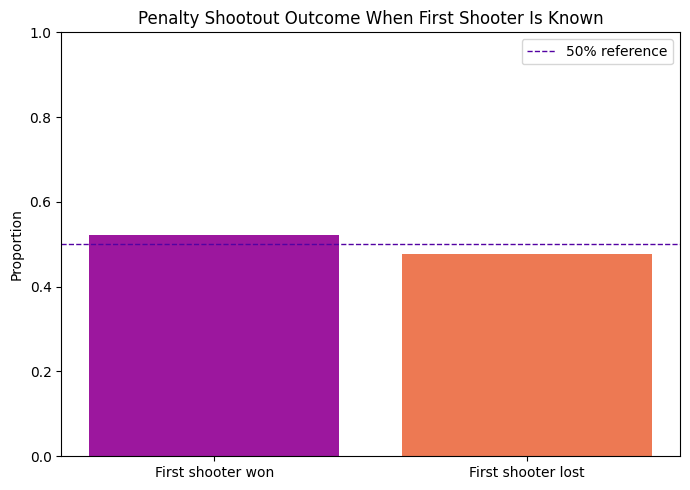

In [30]:
shootout_rates = pd.Series({
    'First shooter won': shootouts_known['first_shooter_won'].mean(),
    'First shooter lost': 1 - shootouts_known['first_shooter_won'].mean()
})

fig, ax = plt.subplots(figsize=(7,5))

ax.bar(
    shootout_rates.index,
    shootout_rates.values,
    color=sns.color_palette('plasma', n_colors=len(shootout_rates))
)

ax.axhline(0.5, linestyle='--', linewidth=1, label='50% reference')
ax.set_ylim(0,1)
ax.set_ylabel('Proportion')
ax.set_title('Penalty Shootout Outcome When First Shooter Is Known')
ax.legend()
plt.tight_layout()
plt.show()


**Interpretation guide:** Compare the observed first-shooter win rate with the 50% reference, but state the coverage limitation. Missing first-shooter information is substantial, so the known subset may not perfectly represent all shootouts.

# Bringing the 2026 evidence together

## Correlation overview of selected success factors

After examining individual domains, a compact correlation overview helps compare their relationships with 2026 success on the same scale. The selection deliberately avoids including every available variable, which would create a large and difficult-to-interpret matrix.

The variables below represent team strength, attack, defence, distribution, physical performance, movement and discipline. Per-match measures are preferred for cumulative totals.

In [31]:
key_features = [
    'fifa_rank',
    'AttemptsAtGoal_per_match','AttemptsOnTarget_per_match','AttemptsAtGoalConversionRatePC','xG','xGEfficiency',
    'GoalsConceded_per_match','clean_sheet_rate','BallRecoveryTime','DirectDefensivePressurePC',
    'PassingAccuracyPC','DefensiveLineBreaksAccPC',
    'AverageSpeed','Sprints_per_match','TotalDistance_per_match',
    'OffersToReceive_per_match','ReceptionsUnderPressure_per_match',
    'YellowCards_per_match','FoulsAgainst_per_match'
]

key_corr = team_eda[key_features + ['win_rate','matches_played']].corr(numeric_only=True)
relationship_table = key_corr[['win_rate','matches_played']].drop(['win_rate','matches_played'])
relationship_table['abs_win_rate_corr'] = relationship_table['win_rate'].abs()
relationship_table.sort_values('abs_win_rate_corr', ascending=False).round(3)

,win_rate,matches_played,abs_win_rate_corr
xG,0.847,0.906,0.847
fifa_rank,-0.710,-0.594,0.710
AttemptsOnTarget_per_match,0.692,0.636,0.692
PassingAccuracyPC,0.675,0.470,0.675
BallRecoveryTime,0.648,0.845,0.648
OffersToReceive_per_match,0.602,0.474,0.602
GoalsConceded_per_match,-0.598,-0.487,0.598
DefensiveLineBreaksAccPC,0.567,0.470,0.567
AttemptsAtGoal_per_match,0.527,0.439,0.527
clean_sheet_rate,0.513,0.473,0.513


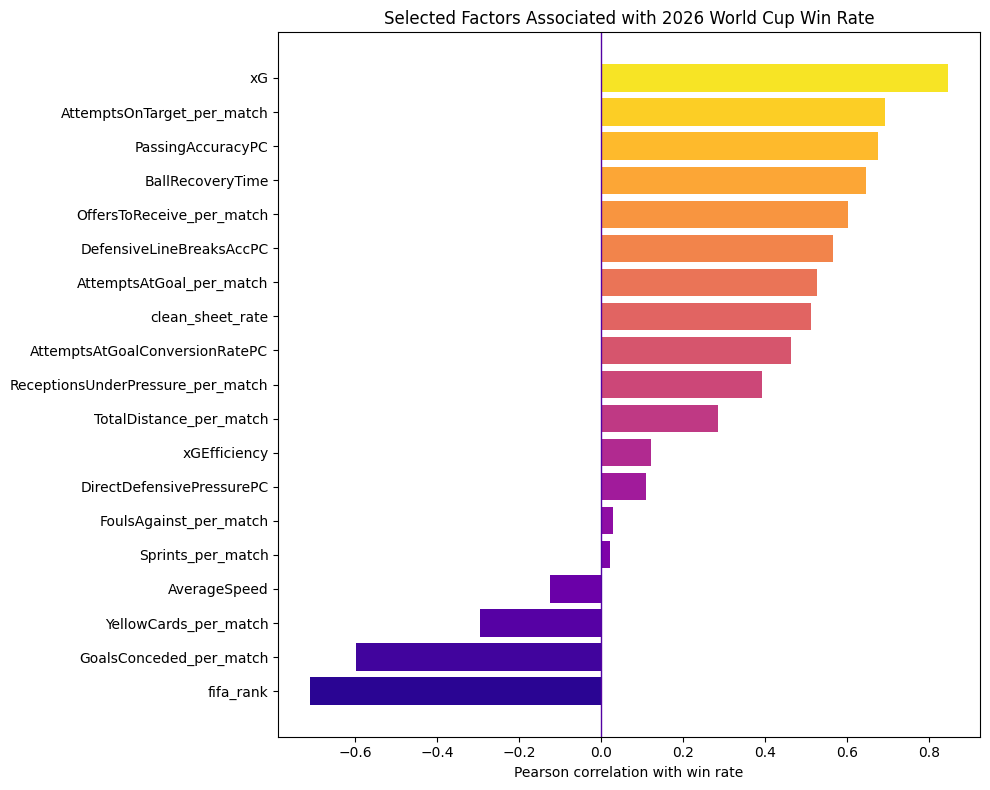

In [32]:
ranked = relationship_table.sort_values('win_rate')['win_rate']

fig, ax = plt.subplots(figsize=(10,8))

ax.barh(
    ranked.index,
    ranked.values,
    color=sns.color_palette('plasma', n_colors=len(ranked))
)

ax.axvline(0, linewidth=1)
ax.set_title('Selected Factors Associated with 2026 World Cup Win Rate')
ax.set_xlabel('Pearson correlation with win rate')
plt.tight_layout()
plt.show()


**Interpretation guide:** This chart is a comparative summary, not a feature-selection rule. Strong correlations can be useful signals, but related variables may measure the same underlying behaviour. The ML stage should consider multicollinearity, leakage and whether each feature would genuinely be available at prediction time.

## Attack versus defence: which is more strongly associated with success?

This section directly compares simple, interpretable attacking and defensive indicators rather than relying on composite scores. This avoids duplicating the existing team radar analysis.

- Attack is represented by goals scored per match and conversion rate.
- Defence is represented by goals conceded per match and clean-sheet rate.

The absolute correlation magnitudes are compared because successful defence naturally produces a **negative** relationship for goals conceded.

In [33]:
attack_defence_compare = pd.Series({
    'Goals scored per match': team_eda['Goals_per_match'].corr(team_eda['win_rate']) if 'Goals_per_match' in team_eda.columns else team_eda['goals_for_per_match'].corr(team_eda['win_rate']),
    'Shot conversion rate': team_eda['AttemptsAtGoalConversionRatePC'].corr(team_eda['win_rate']),
    'Goals conceded per match': team_eda['GoalsConceded_per_match'].corr(team_eda['win_rate']),
    'Clean-sheet rate': team_eda['clean_sheet_rate'].corr(team_eda['win_rate'])
}).sort_values(key=lambda s: s.abs(), ascending=False)

attack_defence_compare.to_frame('Correlation_with_win_rate').round(3)

,Correlation_with_win_rate
Goals scored per match,0.710
Goals conceded per match,-0.598
Clean-sheet rate,0.513
Shot conversion rate,0.464


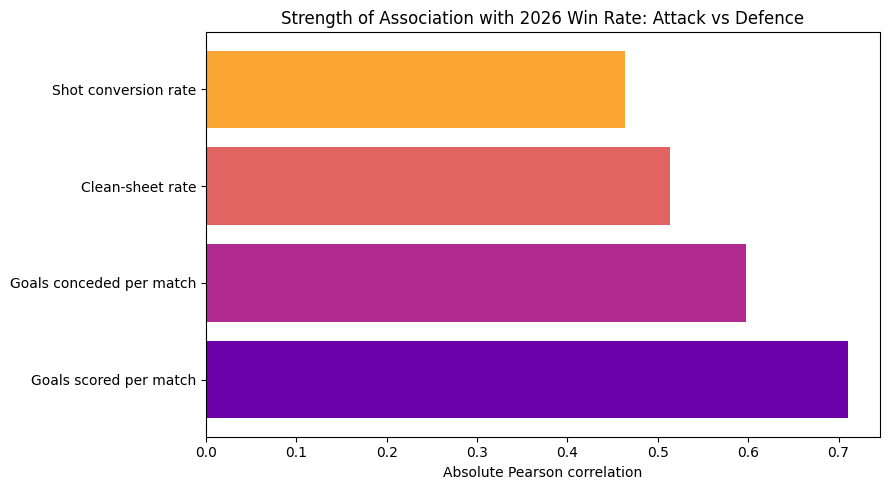

In [34]:
fig, ax = plt.subplots(figsize=(9,5))
ax.barh(
    attack_defence_compare.index,
    attack_defence_compare.abs().values,
    color=sns.color_palette('plasma', n_colors=len(attack_defence_compare)))

ax.set_title('Strength of Association with 2026 Win Rate: Attack vs Defence')
ax.set_xlabel('Absolute Pearson correlation')
plt.tight_layout()
plt.show()


**Interpretation guide:** The larger absolute coefficient indicates the stronger linear association in this dataset. This does not mean one domain is universally more important than the other, and it does not account for interactions between attack and defence. It does provide evidence for which variables deserve closer attention in later modelling.

## EDA summary table (strongest observed 2026 relationships)

This final code cell automatically lists the strongest selected relationships with win rate. It provides a reproducible starting point for the written conclusion rather than manually choosing only visually impressive findings.

In [35]:
eda_summary = (relationship_table[['win_rate','matches_played']]
               .assign(abs_win_rate=lambda d: d['win_rate'].abs())
               .sort_values('abs_win_rate', ascending=False))
print('Top 10 selected factors by absolute correlation with 2026 win rate:')
display(eda_summary.head(10).round(3))

Top 10 selected factors by absolute correlation with 2026 win rate:


,win_rate,matches_played,abs_win_rate
xG,0.847,0.906,0.847
fifa_rank,-0.710,-0.594,0.710
AttemptsOnTarget_per_match,0.692,0.636,0.692
PassingAccuracyPC,0.675,0.470,0.675
BallRecoveryTime,0.648,0.845,0.648
OffersToReceive_per_match,0.602,0.474,0.602
GoalsConceded_per_match,-0.598,-0.487,0.598
DefensiveLineBreaksAccPC,0.567,0.470,0.567
AttemptsAtGoal_per_match,0.527,0.439,0.527
clean_sheet_rate,0.513,0.473,0.513


# Conclusions and implications for machine learning

After running all cells, use the outputs above to complete the final interpretation. The conclusion should answer the research question rather than simply repeat chart titles.

### Team-level success
Record which factors showed the strongest relationships with `win_rate` and `matches_played`. Pay particular attention to whether FIFA ranking, attacking efficiency, defensive performance, distribution, physical performance, movement or discipline provided the clearest signals.

### Match-level outcomes
Report the observed probability of winning after scoring first and whether the timing of the opening goal changed that relationship. Summarise the prevalence of penalty goals and own goals. For shootouts, report the first-shooter result together with the proportion of shootouts for which first-shooter information was actually known.

### Important limitations
- 2026 detailed performance metrics describe the same tournament whose success is being measured. They are useful for explaining **what characterised successful teams**, but many would constitute leakage if used to predict the tournament before it occurred.
- Tournament totals are affected by matches played; this notebook therefore uses per-match measures where appropriate.
- Correlation is not causation.
- Some variables are related to one another and should not automatically all enter the same model.
- The shootout first-shooter analysis uses only records with known first-shooter information.
- Event-level analyses depend on the coverage and definitions of the goalscorer dataset.

### Handover to ML
The next stage should use the EDA findings to guide feature engineering, but prediction features must be restricted to information available **before the match being predicted**. Historical form, prior results, ranking and other pre-match measures are suitable candidates. Same-match outcomes such as final goals, tournament-wide 2026 totals calculated after later matches, or whether a team scored first cannot be used as pre-match predictors without causing data leakage.

## Reproducibility check

The final cell records the core analysis dimensions. These checks make it easier to notice accidental changes to the data or merge logic if the notebook is rerun later.

In [36]:
print('=== EDA REPRODUCIBILITY CHECK ===')
print('2026 completed World Cup matches:', len(results_2026))
print('2026 teams in success table:', team_success['team'].nunique())
print('2026 teams in merged EDA table:', team_eda['Team'].nunique())
print('Historical completed World Cup matches:', len(wc_results))
print('World Cup matches with identifiable first goal:', len(first_goal_matches))
print('Shootouts with known first shooter:', len(shootouts_known))
print('Duplicate teams in team_eda:', team_eda['Team'].duplicated().sum())

=== EDA REPRODUCIBILITY CHECK ===
2026 completed World Cup matches: 104
2026 teams in success table: 48
2026 teams in merged EDA table: 48
Historical completed World Cup matches: 1068
World Cup matches with identifiable first goal: 974
Shootouts with known first shooter: 260
Duplicate teams in team_eda: 0
